**Data Cleaning**

In this section, missing values are handled, duplicate records are checked, and a datetime column is created to prepare the dataset for analysis.

In [ ]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

pd.set_option('display.float_format', '{:.2f}'.format)

In [ ]:
import glob
csv_files = glob.glob("*.csv")

print("CSV Files Found:")
for file in csv_files:
    print(file)

print("\nTotal CSV Files Found:", len(csv_files))

CSV Files Found:
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv

Total CSV Files Found: 12


In [ ]:
df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,5.00,14.00,4.00,12.00,200.00,85.00,-0.50,1024.50,-21.40,0.00,NNW,5.70,Nongzhanguan
1,2,2013,3,1,1,8.00,12.00,6.00,14.00,200.00,84.00,-0.70,1025.10,-22.10,0.00,NW,3.90,Nongzhanguan
2,3,2013,3,1,2,3.00,6.00,5.00,14.00,200.00,83.00,-1.20,1025.30,-24.60,0.00,NNW,5.30,Nongzhanguan
3,4,2013,3,1,3,5.00,5.00,5.00,14.00,200.00,84.00,-1.40,1026.20,-25.50,0.00,N,4.90,Nongzhanguan
4,5,2013,3,1,4,5.00,5.00,6.00,21.00,200.00,77.00,-1.90,1027.10,-24.50,0.00,NNW,3.20,Nongzhanguan


In [ ]:
print("Shape of the dataset:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Shape of the dataset: (420768, 18)

Column Names:
Index(['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2',
       'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     4203

In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

# Display both the count and percentage
print("Missing Values in Each Column:\n")

for column in df.columns:
  print(f"{column}: {missing_values[column]} ({missing_percentage[column]:.2f}%)")

Missing Values in Each Column:

No: 0 (0.00%)
year: 0 (0.00%)
month: 0 (0.00%)
day: 0 (0.00%)
hour: 0 (0.00%)
PM2.5: 8739 (2.08%)
PM10: 6449 (1.53%)
SO2: 9021 (2.14%)
NO2: 12116 (2.88%)
CO: 20701 (4.92%)
O3: 13277 (3.16%)
TEMP: 398 (0.09%)
PRES: 393 (0.09%)
DEWP: 403 (0.10%)
RAIN: 390 (0.09%)
wd: 1822 (0.43%)
WSPM: 318 (0.08%)
station: 0 (0.00%)


In [ ]:
df = df.ffill()

df['wd'] = df['wd'].fillna(df['wd'].mode()[0])

print("Remaining Missing Values:\n")
print(df.isnull().sum())

Remaining Missing Values:

No         0
year       0
month      0
day        0
hour       0
PM2.5      0
PM10       0
SO2        0
NO2        0
CO         0
O3         0
TEMP       0
PRES       0
DEWP       0
RAIN       0
wd         0
WSPM       0
station    0
dtype: int64


In [ ]:
duplicate_rows = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_rows)

Number of Duplicate Rows: 0


In [ ]:
columns = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO',
           'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

print(df[columns].describe())

          PM2.5      PM10       SO2       NO2        CO        O3      TEMP  \
count 420768.00 420768.00 420768.00 420768.00 420768.00 420768.00 420768.00   
mean      80.15    105.06     15.93     50.54   1240.24     57.44     13.53   
std       81.30     92.67     22.28     35.31   1170.86     58.31     11.44   
min        2.00      2.00      0.29      1.03    100.00      0.21    -19.90   
25%       20.00     36.00      3.00     23.00    500.00     10.00      3.10   
50%       55.00     82.00      7.00     43.00    900.00     44.00     14.50   
75%      112.00    146.00     20.00     71.00   1500.00     82.00     23.30   
max      999.00    999.00    500.00    290.00  10000.00   1071.00     41.60   

           PRES      DEWP      RAIN      WSPM  
count 420768.00 420768.00 420768.00 420768.00  
mean    1010.75      2.48      0.06      1.73  
std       10.47     13.80      0.82      1.25  
min      982.40    -43.40      0.00      0.00  
25%     1002.30     -8.90      0.00      0.90  


In [ ]:
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])

# Display the first 5 rows
df[['datetime', 'year', 'month', 'day', 'hour']].head()

,datetime,year,month,day,hour
0,2013-03-01 00:00:00,2013,3,1,0
1,2013-03-01 01:00:00,2013,3,1,1
2,2013-03-01 02:00:00,2013,3,1,2
3,2013-03-01 03:00:00,2013,3,1,3
4,2013-03-01 04:00:00,2013,3,1,4


In [ ]:
print(df['station'].value_counts())

station
Nongzhanguan     35064
Dingling         35064
Huairou          35064
Changping        35064
Guanyuan         35064
Dongsi           35064
Shunyi           35064
Wanshouxigong    35064
Aotizhongxin     35064
Gucheng          35064
Wanliu           35064
Tiantan          35064
Name: count, dtype: int64


**Exploratory Data Analysis (EDA)**

This section explores the dataset using statistical summaries and visualizations to understand the distribution of PM2.5, identify outliers, examine temporal trends, and investigate relationships among variables.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

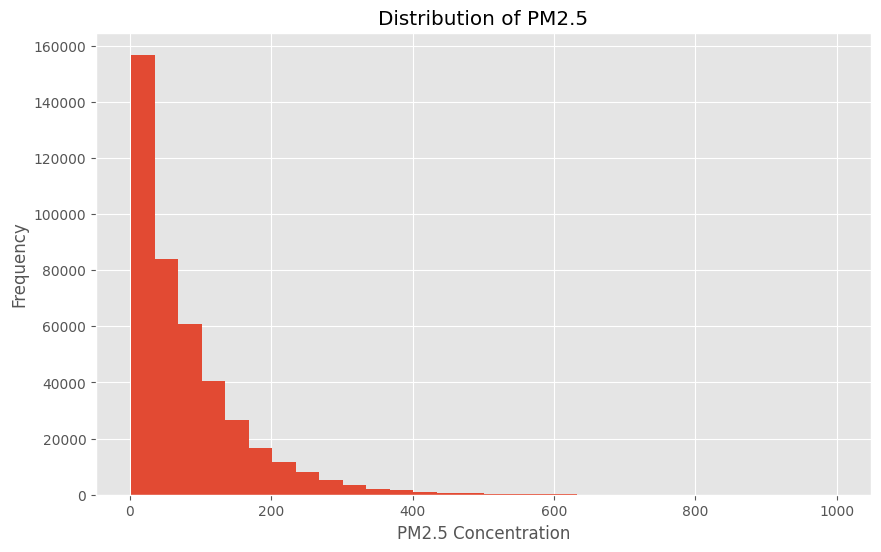

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(df['PM2.5'], bins=30)

plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")

plt.show()

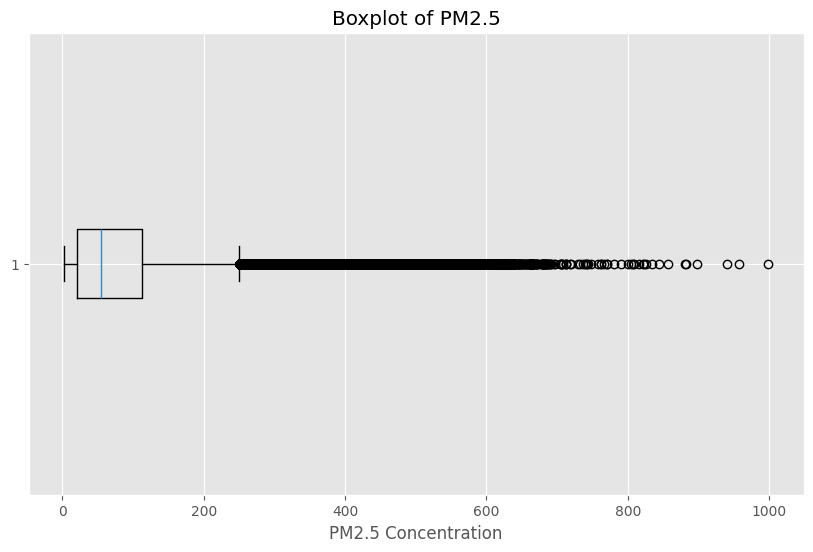

In [ ]:
plt.figure(figsize=(10, 6))

plt.boxplot(df['PM2.5'], vert=False)

plt.title("Boxplot of PM2.5")
plt.xlabel("PM2.5 Concentration")

plt.show()

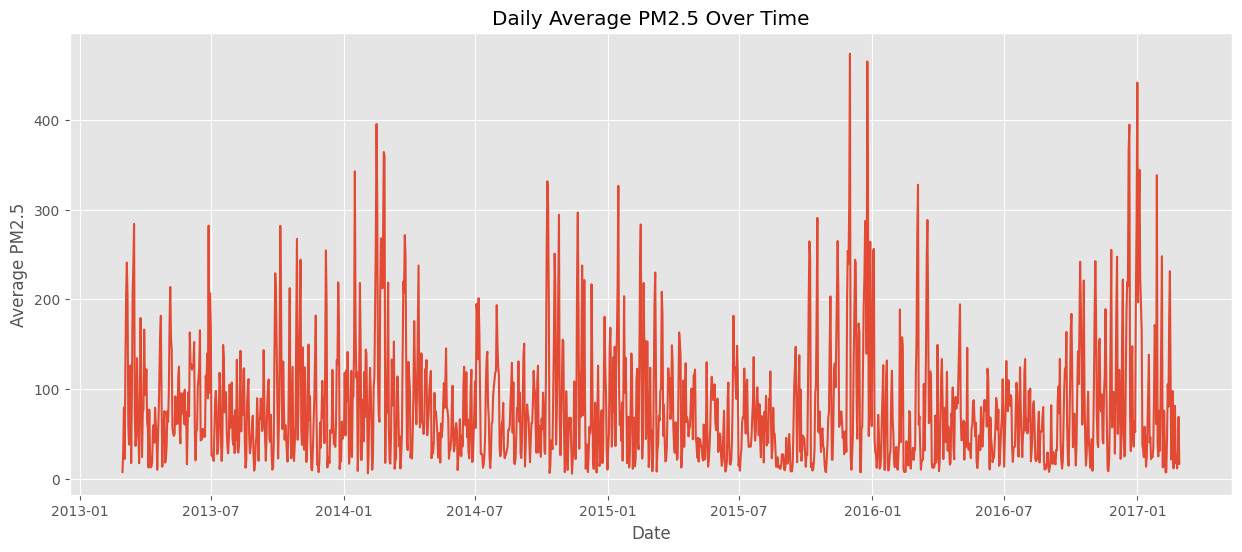

In [ ]:
daily_pm25 = df.groupby(df['datetime'].dt.date)['PM2.5'].mean()


plt.figure(figsize=(15, 6))

plt.plot(daily_pm25.index, daily_pm25.values)

plt.title("Daily Average PM2.5 Over Time")
plt.xlabel("Date")
plt.ylabel("Average PM2.5")

plt.show()

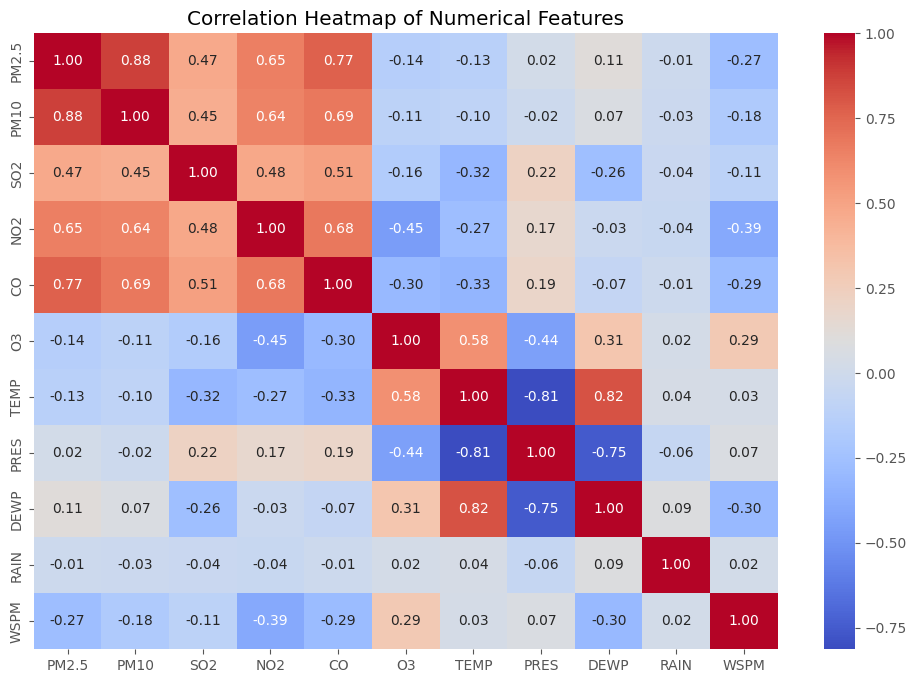

In [ ]:
correlation_columns = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

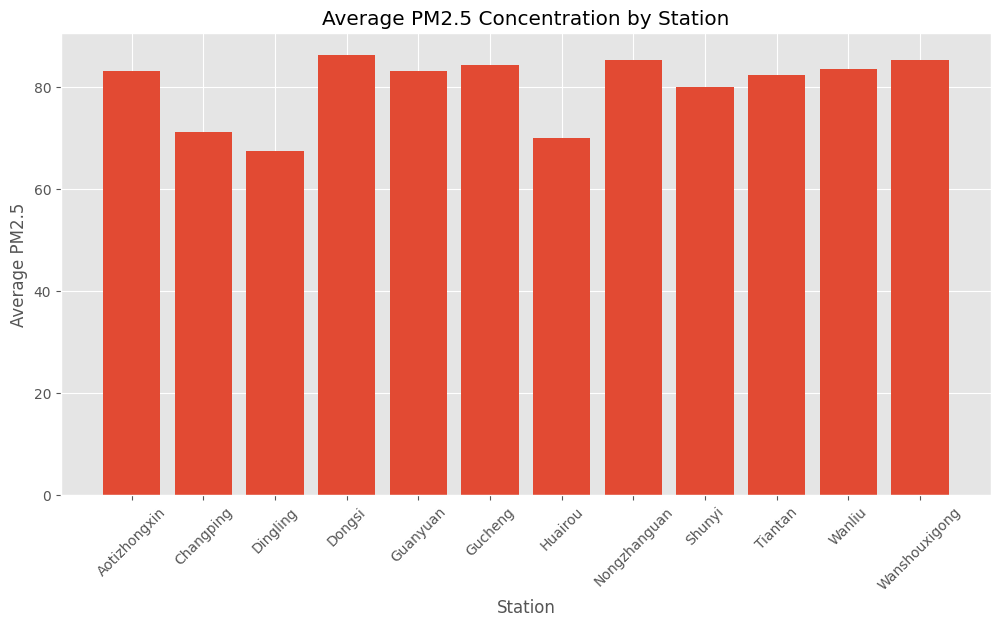

In [ ]:
station_pm25 = df.groupby('station')['PM2.5'].mean()

plt.figure(figsize=(12, 6))

plt.bar(station_pm25.index, station_pm25.values)

plt.title("Average PM2.5 Concentration by Station")
plt.xlabel("Station")
plt.ylabel("Average PM2.5")

plt.xticks(rotation=45)

plt.show()

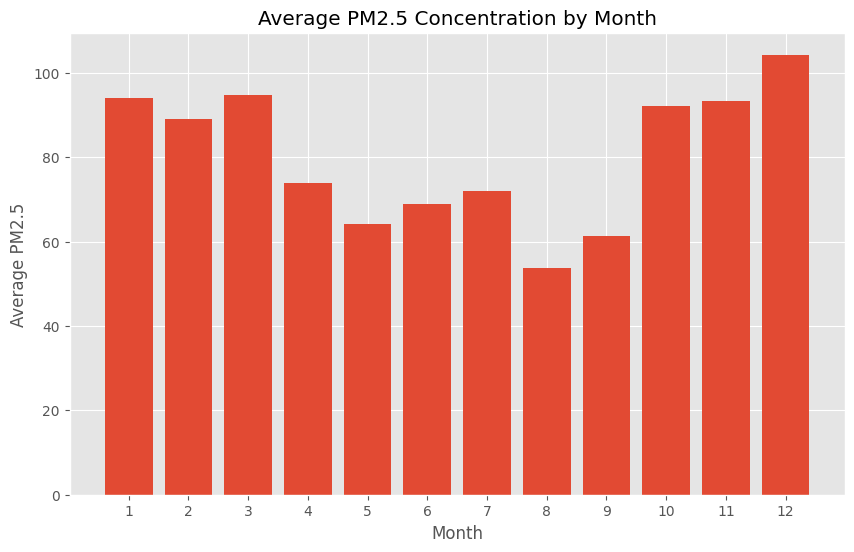

In [ ]:
monthly_pm25 = df.groupby('month')['PM2.5'].mean()


plt.figure(figsize=(10, 6))

plt.bar(monthly_pm25.index, monthly_pm25.values)

plt.title("Average PM2.5 Concentration by Month")
plt.xlabel("Month")
plt.ylabel("Average PM2.5")

plt.xticks(range(1, 13))

plt.show()

**Feature Engineering**

In this section, categorical variables are encoded, a next-hour PM2.5 target variable is created for forecasting, and unnecessary columns are removed to prepare the dataset for machine learning.

In [ ]:
df = df.sort_values(by=['station', 'datetime'])

df = df.reset_index(drop=True)

df[['station', 'datetime', 'PM2.5']].head()

,station,datetime,PM2.5
0,Aotizhongxin,2013-03-01 00:00:00,4.00
1,Aotizhongxin,2013-03-01 01:00:00,8.00
2,Aotizhongxin,2013-03-01 02:00:00,7.00
3,Aotizhongxin,2013-03-01 03:00:00,6.00
4,Aotizhongxin,2013-03-01 04:00:00,3.00


In [ ]:
from sklearn.preprocessing import LabelEncoder

station_encoder = LabelEncoder()
wd_encoder = LabelEncoder()

df['station'] = station_encoder.fit_transform(df['station'])
df['wd'] = wd_encoder.fit_transform(df['wd'])

df[['station', 'wd']].head(10)

,station,wd
0,0,6
1,0,3
2,0,6
3,0,7
4,0,3
5,0,3
6,0,5
7,0,6
8,0,6
9,0,3


In [ ]:
df['target_PM2.5'] = df.groupby('station')['PM2.5'].shift(-1)


df = df.dropna(subset=['target_PM2.5'])


df = df.reset_index(drop=True)

df[['station', 'datetime', 'PM2.5', 'target_PM2.5']].head(10)

,station,datetime,PM2.5,target_PM2.5
0,0,2013-03-01 00:00:00,4.00,8.00
1,0,2013-03-01 01:00:00,8.00,7.00
2,0,2013-03-01 02:00:00,7.00,6.00
3,0,2013-03-01 03:00:00,6.00,3.00
4,0,2013-03-01 04:00:00,3.00,5.00
5,0,2013-03-01 05:00:00,5.00,3.00
6,0,2013-03-01 06:00:00,3.00,3.00
7,0,2013-03-01 07:00:00,3.00,3.00
8,0,2013-03-01 08:00:00,3.00,3.00
9,0,2013-03-01 09:00:00,3.00,3.00


In [ ]:
df = df.drop(columns=['No', 'datetime'])

df.head()

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,target_PM2.5
0,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,1023.00,-18.80,0.00,6,4.40,0,8.00
1,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,1023.20,-18.20,0.00,3,4.70,0,7.00
2,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,1023.50,-18.20,0.00,6,5.60,0,6.00
3,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,1024.50,-19.40,0.00,7,3.10,0,3.00
4,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,1025.20,-19.50,0.00,3,2.00,0,5.00


**Model Development, Evaluation & Comparison**

In [ ]:
X = df.drop(columns=['target_PM2.5'])

y = df['target_PM2.5']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (420756, 17)
Shape of y: (420756,)


In [ ]:
df = df.sort_values(
    by=['year', 'month', 'day', 'hour', 'station']
).reset_index(drop=True)


X = df.drop(columns=['target_PM2.5'])
y = df['target_PM2.5']


df[['year', 'month', 'day', 'hour', 'station', 'PM2.5', 'target_PM2.5']].head(10)

,year,month,day,hour,station,PM2.5,target_PM2.5
0,2013,3,1,0,0,4.00,8.00
1,2013,3,1,0,1,3.00,3.00
2,2013,3,1,0,2,4.00,7.00
3,2013,3,1,0,3,9.00,4.00
4,2013,3,1,0,4,4.00,4.00
5,2013,3,1,0,5,6.00,6.00
6,2013,3,1,0,6,7.00,4.00
7,2013,3,1,0,7,5.00,8.00
8,2013,3,1,0,8,3.00,12.00
9,2013,3,1,0,9,6.00,6.00


In [ ]:
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (336604, 17)
Testing data: (84152, 17)


In [ ]:
print("Training period:")
print(X_train[['year', 'month', 'day', 'hour']].iloc[0])
print("to")
print(X_train[['year', 'month', 'day', 'hour']].iloc[-1])

print("\nTesting period:")
print(X_test[['year', 'month', 'day', 'hour']].iloc[0])
print("to")
print(X_test[['year', 'month', 'day', 'hour']].iloc[-1])

Training period:
year     2013
month       3
day         1
hour        0
Name: 0, dtype: int64
to
year     2016
month       5
day        12
hour       18
Name: 336603, dtype: int64

Testing period:
year     2016
month       5
day        12
hour       18
Name: 336604, dtype: int64
to
year     2017
month       2
day        28
hour       22
Name: 420755, dtype: int64


In [ ]:
time_value = pd.to_datetime(
    df[['year', 'month', 'day', 'hour']]
)

cutoff_time = time_value.iloc[split_index]

train_mask = time_value < cutoff_time
test_mask = time_value >= cutoff_time

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Cutoff time:", cutoff_time)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

Cutoff time: 2016-05-12 18:00:00

Training data: (336600, 17)
Testing data: (84156, 17)


In [ ]:
baseline_predictions = X_test['PM2.5']

print("First 10 Baseline Predictions:")
print(baseline_predictions.head(10))

First 10 Baseline Predictions:
336600   10.00
336601   18.00
336602   29.00
336603    3.00
336604   10.00
336605   19.00
336606    7.00
336607   18.00
336608    6.00
336609   15.00
Name: PM2.5, dtype: float64


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Persistence Baseline Results:")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R² Score:", baseline_r2)

Persistence Baseline Results:
MAE: 9.98753505394743
RMSE: 19.624205148985137
R² Score: 0.9450083902535557


In [ ]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("First 10 Linear Regression Predictions:")
print(lr_predictions[:10])

First 10 Linear Regression Predictions:
[ 7.28341722 16.68486826 26.97463966  1.55666221  7.23868544 16.33509131
  5.92924109 15.01912291  6.10767321 11.8558318 ]


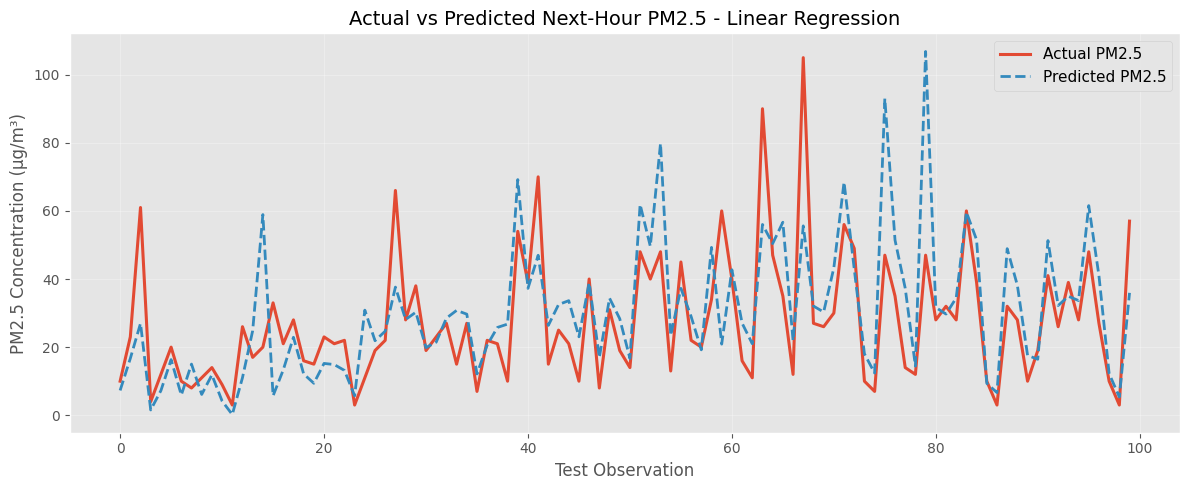

In [ ]:
import matplotlib.pyplot as plt

n = 100

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:n].values,
    label='Actual PM2.5',
    linewidth=2.2
)

plt.plot(
    lr_predictions[:n],
    label='Predicted PM2.5',
    linewidth=2.0,
    linestyle='--'
)

plt.xlabel('Test Observation', fontsize=12)
plt.ylabel('PM2.5 Concentration (µg/m³)', fontsize=12)
plt.title(
    'Actual vs Predicted Next-Hour PM2.5 - Linear Regression',
    fontsize=14
)

plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results:")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R² Score:", lr_r2)

Linear Regression Results:
MAE: 10.153292152549627
RMSE: 19.189524539997425
R² Score: 0.9474175629135928


In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("First 10 Decision Tree Predictions:")
print(dt_predictions[:10])

First 10 Decision Tree Predictions:
[13. 20. 15. 18. 11.  3.  5. 28. 12. 14.]


In [ ]:
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Results:")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R² Score:", dt_r2)

Decision Tree Results:
MAE: 17.057634630923523
RMSE: 32.27307969445269
R² Score: 0.8512718749366546


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("First 10 Random Forest Predictions:")
print(rf_predictions[:10])

First 10 Random Forest Predictions:
[11.26 16.89 26.73 10.57 11.07 18.76  8.05 19.85 10.07 12.98]


In [ ]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results:")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Results:
MAE: 10.421931448738059
RMSE: 20.170962208598446
R² Score: 0.9419014205605146


In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print("First 10 XGBoost Predictions:")
print(xgb_predictions[:10])

First 10 XGBoost Predictions:
[11.576006 16.829607 27.991535  9.307068 11.646365 17.527933  9.366787
 18.046465  9.920394 13.801902]


In [ ]:
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBoost Results:")
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("R² Score:", xgb_r2)

XGBoost Results:
MAE: 12.036582881338612
RMSE: 21.993659770678978
R² Score: 0.930927164078102


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Persistence Baseline',
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],

    'MAE': [
        baseline_mae,
        lr_mae,
        dt_mae,
        rf_mae,
        xgb_mae
    ],

    'RMSE': [
        baseline_rmse,
        lr_rmse,
        dt_rmse,
        rf_rmse,
        xgb_rmse
    ],

    'R2 Score': [
        baseline_r2,
        lr_r2,
        dt_r2,
        rf_r2,
        xgb_r2
    ]
})

results = results.round(4)

results

,Model,MAE,RMSE,R2 Score
0,Persistence Baseline,9.99,19.62,0.94
1,Linear Regression,10.15,19.19,0.95
2,Decision Tree,17.06,32.27,0.85
3,Random Forest,10.42,20.17,0.94
4,XGBoost,12.04,21.99,0.93


In [ ]:
year_counts = df['year'].value_counts().sort_index()

print("Number of observations in each year:")
print(year_counts)

Number of observations in each year:
year
2013     88128
2014    105120
2015    105120
2016    105408
2017     16980
Name: count, dtype: int64


In [ ]:
rolling_folds = [
    ([2013], 2014),
    ([2013, 2014], 2015),
    ([2013, 2014, 2015], 2016)
]

print("Rolling validation folds:")

for train_years, test_year in rolling_folds:
    print("Train:", train_years, "-> Validate:", test_year)

Rolling validation folds:
Train: [2013] -> Validate: 2014
Train: [2013, 2014] -> Validate: 2015
Train: [2013, 2014, 2015] -> Validate: 2016


In [ ]:
rolling_results = []

for train_years, test_year in rolling_folds:


    train_data = df[df['year'].isin(train_years)]
    test_data = df[df['year'] == test_year]


    X_train_roll = train_data.drop(columns=['target_PM2.5'])
    y_train_roll = train_data['target_PM2.5']

    X_test_roll = test_data.drop(columns=['target_PM2.5'])
    y_test_roll = test_data['target_PM2.5']


    roll_model = LinearRegression()
    roll_model.fit(X_train_roll, y_train_roll)


    roll_predictions = roll_model.predict(X_test_roll)


    roll_mae = mean_absolute_error(y_test_roll, roll_predictions)
    roll_rmse = np.sqrt(mean_squared_error(y_test_roll, roll_predictions))
    roll_r2 = r2_score(y_test_roll, roll_predictions)


    rolling_results.append([
        str(train_years),
        test_year,
        roll_mae,
        roll_rmse,
        roll_r2
    ])

print("Rolling validation completed.")

Rolling validation completed.


In [ ]:
rolling_results_df = pd.DataFrame(
    rolling_results,
    columns=['Training Years', 'Validation Year', 'MAE', 'RMSE', 'R2 Score']
)

rolling_results_df = rolling_results_df.round(4)

rolling_results_df

,Training Years,Validation Year,MAE,RMSE,R2 Score
0,[2013],2014,11.00,19.87,0.94
1,"[2013, 2014]",2015,10.61,19.77,0.94
2,"[2013, 2014, 2015]",2016,9.83,18.54,0.94


In [ ]:
print(rolling_results_df.to_string(index=False))

    Training Years  Validation Year   MAE  RMSE  R2 Score
            [2013]             2014 11.00 19.87      0.94
      [2013, 2014]             2015 10.61 19.77      0.94
[2013, 2014, 2015]             2016  9.83 18.54      0.94


In [ ]:
average_mae = rolling_results_df['MAE'].mean()
average_rmse = rolling_results_df['RMSE'].mean()
average_r2 = rolling_results_df['R2 Score'].mean()

print("Average Rolling Validation Results:")
print("MAE:", round(average_mae, 2))
print("RMSE:", round(average_rmse, 2))
print("R² Score:", round(average_r2, 4))

Average Rolling Validation Results:
MAE: 10.48
RMSE: 19.4
R² Score: 0.9429


In [ ]:
model_names = [
    'Persistence',
    'Linear Regression',
    'Decision Tree',
    'Random Forest',
    'XGBoost'
]

mae_scores = [
    baseline_mae,
    lr_mae,
    dt_mae,
    rf_mae,
    xgb_mae
]

rmse_scores = [
    baseline_rmse,
    lr_rmse,
    dt_rmse,
    rf_rmse,
    xgb_rmse
]

r2_scores = [
    baseline_r2,
    lr_r2,
    dt_r2,
    rf_r2,
    xgb_r2
]

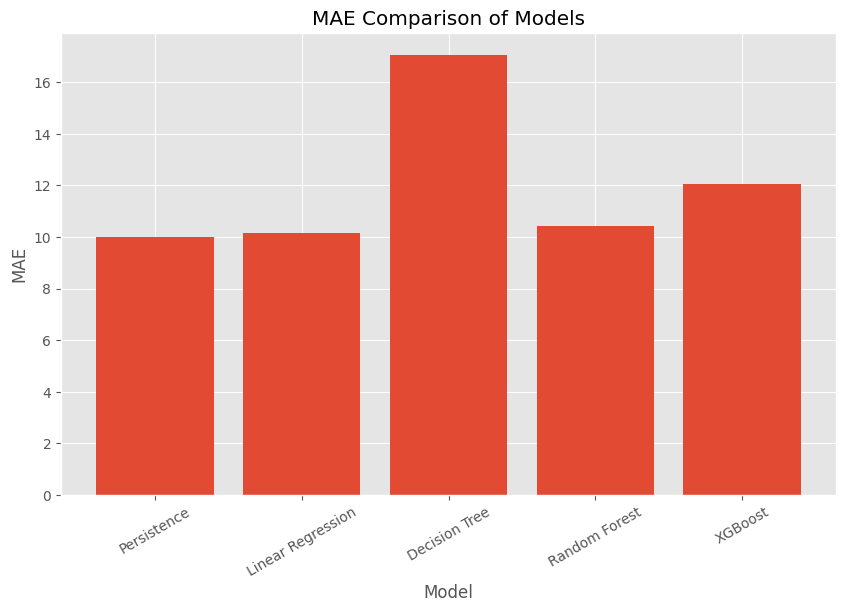

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(model_names, mae_scores)

plt.title("MAE Comparison of Models")
plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(rotation=30)

plt.show()

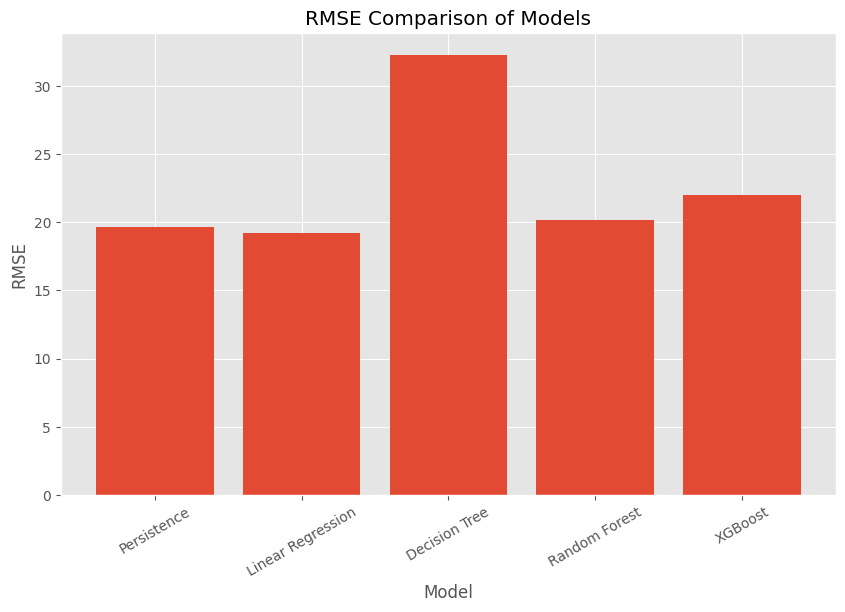

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(model_names, rmse_scores)

plt.title("RMSE Comparison of Models")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.xticks(rotation=30)

plt.show()

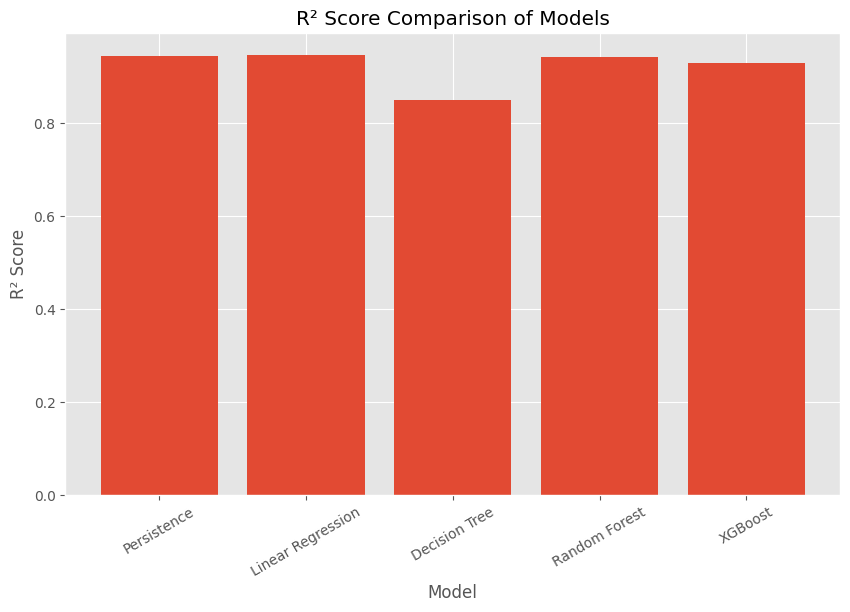

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(model_names, r2_scores)

plt.title("R² Score Comparison of Models")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=30)

plt.show()

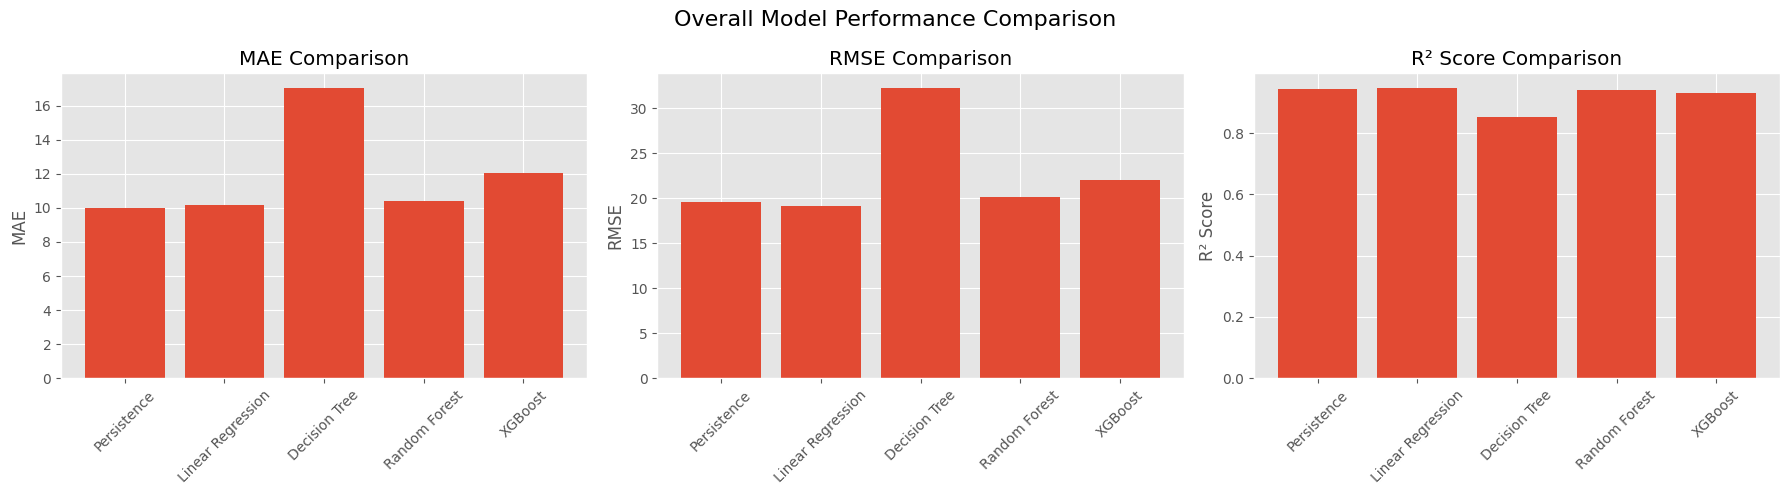

In [ ]:
models = [
    'Persistence',
    'Linear Regression',
    'Decision Tree',
    'Random Forest',
    'XGBoost'
]

mae_scores = [
    baseline_mae,
    lr_mae,
    dt_mae,
    rf_mae,
    xgb_mae
]

rmse_scores = [
    baseline_rmse,
    lr_rmse,
    dt_rmse,
    rf_rmse,
    xgb_rmse
]

r2_scores = [
    baseline_r2,
    lr_r2,
    dt_r2,
    rf_r2,
    xgb_r2
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE
axes[0].bar(models, mae_scores)
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=45)

# RMSE
axes[1].bar(models, rmse_scores)
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=45)

# R²
axes[2].bar(models, r2_scores)
axes[2].set_title("R² Score Comparison")
axes[2].set_ylabel("R² Score")
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle("Overall Model Performance Comparison", fontsize=16)
plt.tight_layout()

plt.show()